# Random slicing loss

In [1]:
import math
import torch

In [2]:
def random_unit_vectors(n_samples: int, dim: int, dtype=torch.float32, device: str="cpu") -> torch.Tensor:
    x = torch.randn(n_samples, dim, dtype=dtype, device=device)
    x = x / x.norm(p=2, dim=1, keepdim=True)
    x.requires_grad_(True)

    return x

In [3]:
def generate_hypercube_data(n_samples: int, dim: int, dtype=torch.float32, device: str="cpu") -> torch.Tensor:
    x = (2.0 * torch.rand(n_samples, dim, dtype=dtype, device=device) - 1.0) * math.sqrt(3.0) # Unit covariance
    x.requires_grad_(True)

    return x

In [4]:
def standartization_loss(x: torch.Tensor, n_projections: int=16) -> torch.Tensor:
    n_samples, dim = x.shape

    W = random_unit_vectors(n_projections, dim, dtype=x.dtype, device=x.device)
    z = x @ W.T
    
    mean = z.mean(dim=0)
    var = z.var(dim=0, unbiased=False)
    
    per_proj = mean.pow(2) + (var - 1.0).pow(2)

    return per_proj.mean()

In [5]:
n_samples = 10000
dim = 100

In [7]:
x = generate_hypercube_data(n_samples, dim, device="mps")

In [8]:
import matplotlib.pyplot as plt

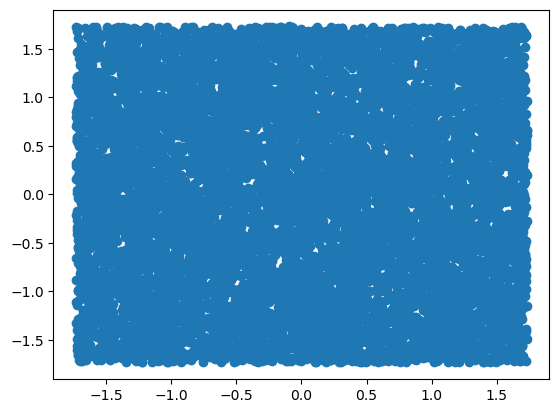

In [9]:
plt.scatter(x[:,0].cpu().detach().numpy(), x[:,1].cpu().detach().numpy())

In [10]:
opt = torch.optim.Adam([x], lr=5e-2)

In [11]:
from tqdm import trange
from pingouin import multivariate_normality

n_steps = 1000
loss_history = []
p_values = []

for step in trange(n_steps):
    opt.zero_grad()
    
    loss = standartization_loss(x)
    loss.backward()

    opt.step()

    loss_history.append(loss.item())

    if step % 100 == 0:
        p_values.append(multivariate_normality(x.detach().cpu().numpy()).pval)

100%|██████████| 1000/1000 [00:13<00:00, 74.74it/s]


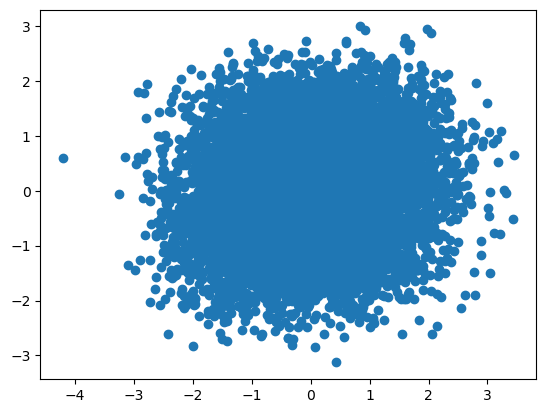

In [12]:
plt.scatter(x[:,0].cpu().detach().numpy(), x[:,1].cpu().detach().numpy())

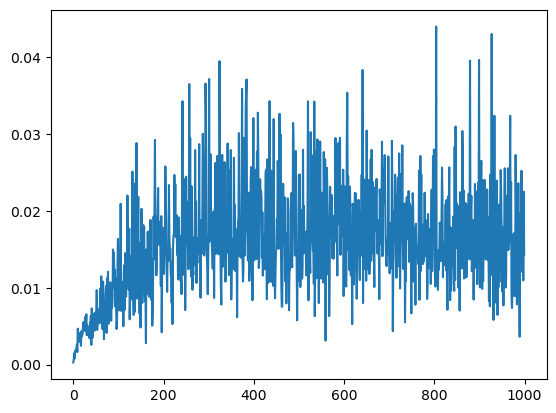

In [13]:
plt.plot(loss_history)

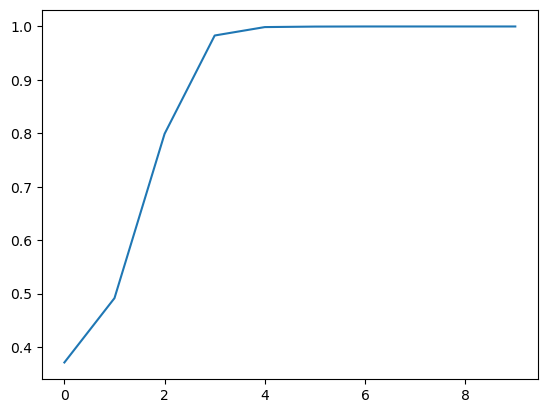

In [14]:
plt.plot(p_values)